In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import seaborn as sns

warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("./Data/heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.shape

(918, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [6]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [7]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
pridic_column = df["HeartDisease"].value_counts()
pridic_column

HeartDisease
1    508
0    410
Name: count, dtype: int64

Text(0.5, 0, 'Heart Patient ')

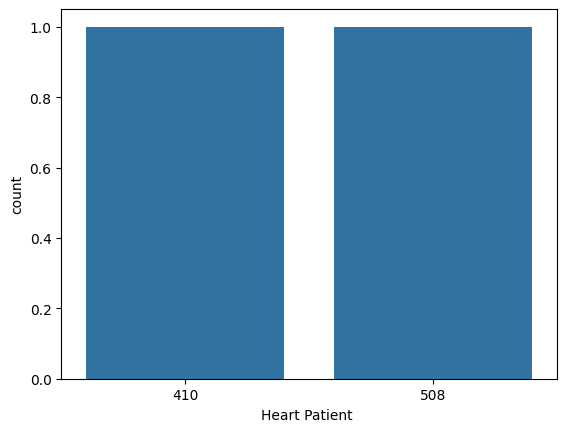

In [10]:
sns.barplot(pridic_column.value_counts())
plt.xlabel("Heart Patient ")

<Axes: xlabel='ChestPainType', ylabel='count'>

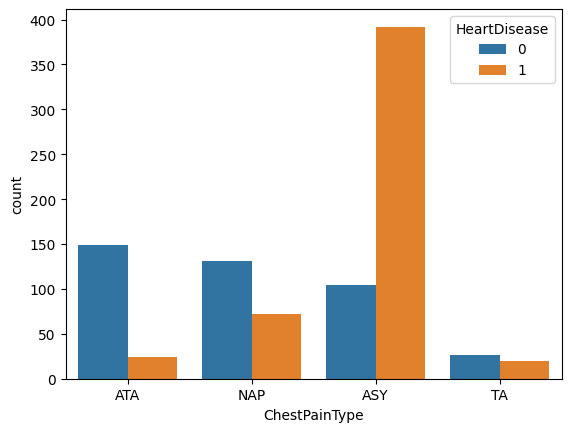

In [11]:
sns.countplot(x= df["ChestPainType"], hue=df["HeartDisease"])

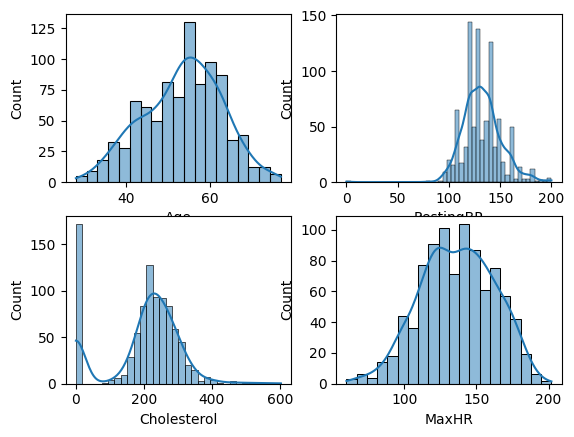

In [12]:
def plotting(var,num):
  plt.subplot(2,2,num)
  sns.histplot(x=df[var], kde=True)

plotting("Age",1)
plotting("RestingBP",2)
plotting("Cholesterol",3)
plotting("MaxHR",4)

In [13]:
df["Cholesterol"].value_counts()

Cholesterol
0      172
254     11
220     10
223     10
204      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [14]:
ch_mean = int(df.loc[df["Cholesterol"] != 0, "Cholesterol"].mean())

In [15]:
df["Cholesterol"] = df["Cholesterol"].replace(0 , ch_mean)

In [16]:
df["Cholesterol"].head()

0    289
1    180
2    283
3    214
4    195
Name: Cholesterol, dtype: int64

In [17]:
RBP_mean = int(df.loc[df["RestingBP"] != 0, "RestingBP"].mean())
df["RestingBP"] = df["RestingBP"].replace(0,RBP_mean)

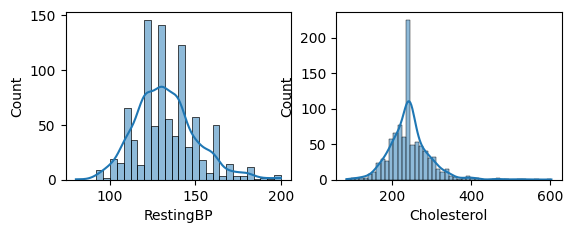

In [18]:
plotting("RestingBP", 1)
plotting("Cholesterol" , 2)

<Axes: xlabel='FastingBS', ylabel='count'>

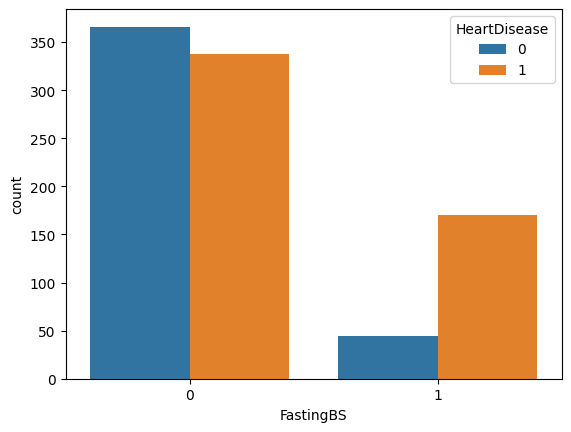

In [19]:
sns.countplot(x = df["FastingBS"],hue=df["HeartDisease"])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

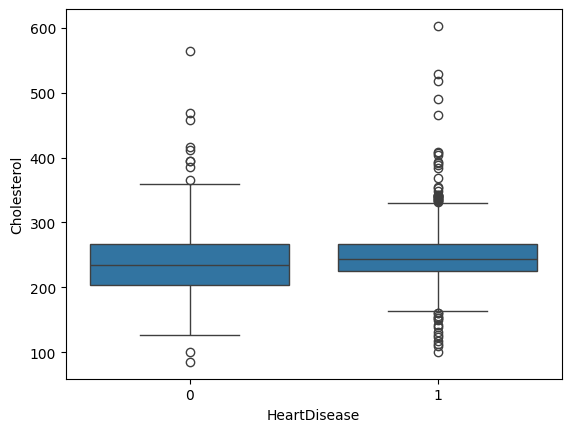

In [20]:
sns.boxplot(x=df["HeartDisease"], y=df["Cholesterol"])

<Axes: xlabel='HeartDisease', ylabel='Age'>

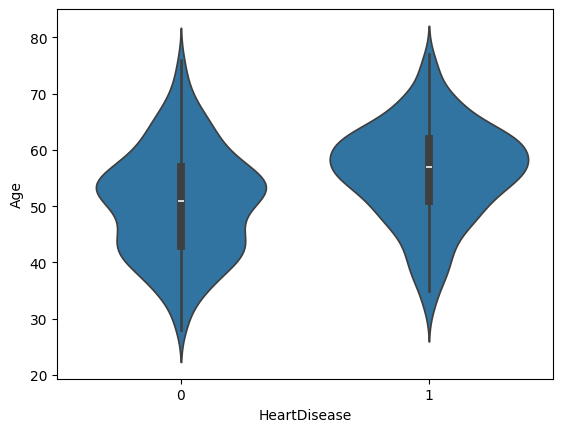

In [21]:
sns.violinplot(y="Age", x="HeartDisease", data=df)

<Axes: >

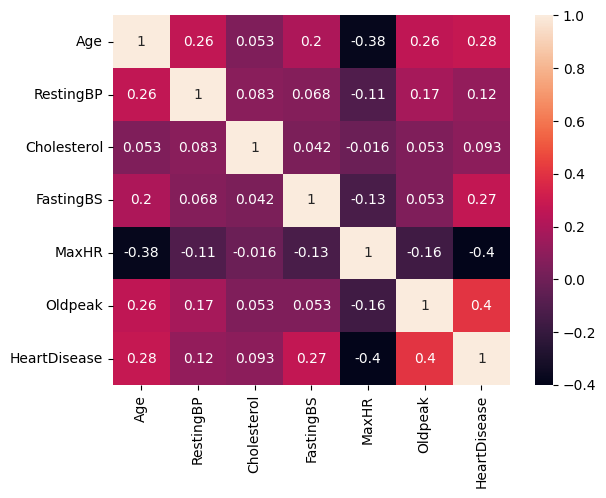

In [22]:
sns.heatmap(df.corr(numeric_only=True), annot= True)

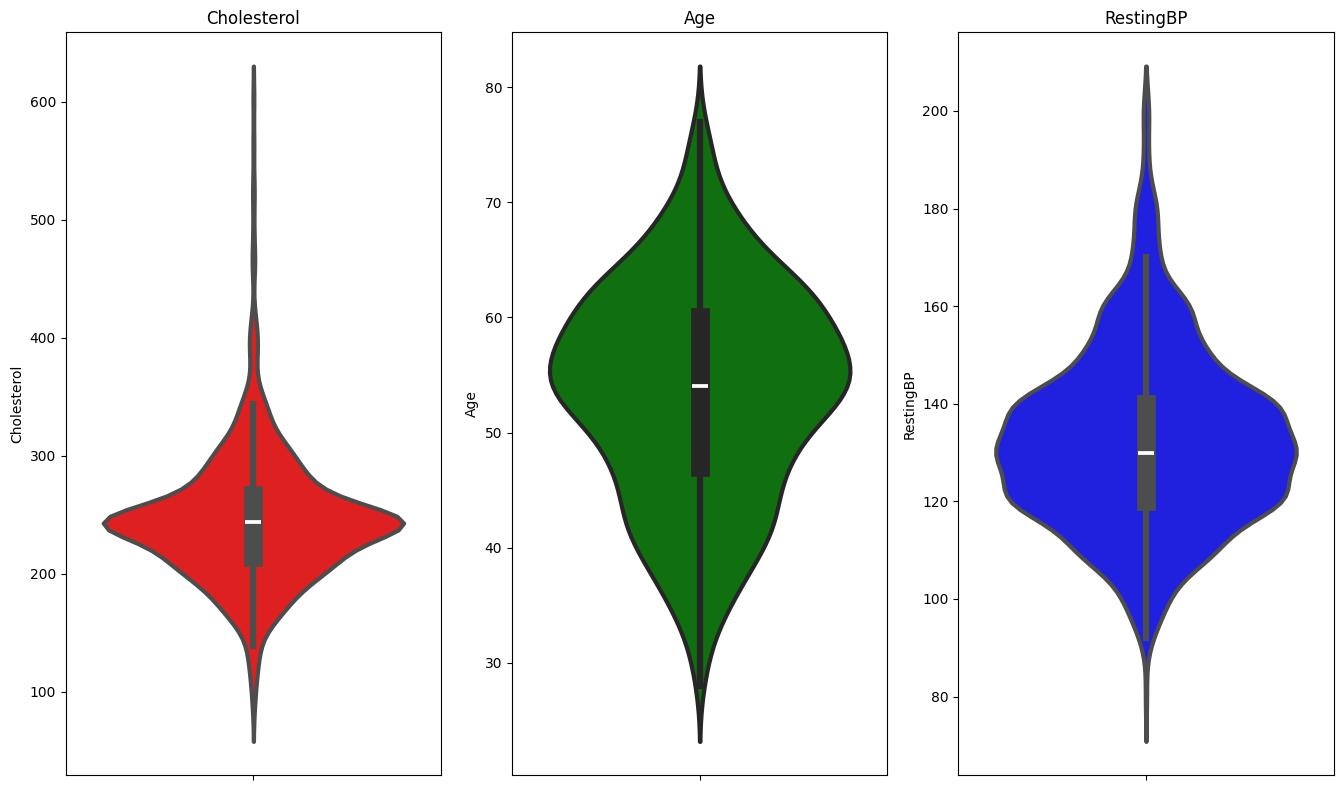

In [23]:
plt.figure(figsize=(18,8))

plt.subplot(1, 4, 1)
plt.title('Cholesterol')
sns.violinplot(y='Cholesterol',data=df,color='red',linewidth=3)

plt.subplot(1, 4, 2)
plt.title('Age')
sns.violinplot(y='Age',data=df,color='green',linewidth=3)

plt.subplot(1, 4, 3)
plt.title('RestingBP')
sns.violinplot(y='RestingBP',data=df,color='blue',linewidth=3)

plt.tight_layout()
plt.show()

(np.float64(-1.25), np.float64(1.25), np.float64(-1.25), np.float64(1.25))

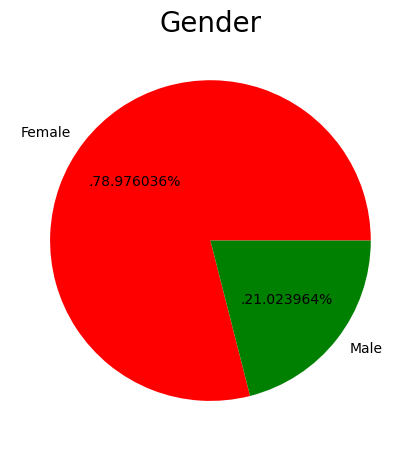

In [24]:
plt.rcParams['figure.figsize'] = (30, 12)

plt.subplot(1, 5, 1)
size = df['Sex'].value_counts()
labels = 'Female', 'Male'
color = ['red','green']


plt.pie(size, colors = color, labels = labels,autopct = '.%2f%%')
plt.title('Gender', fontsize = 20)
plt.axis('off')

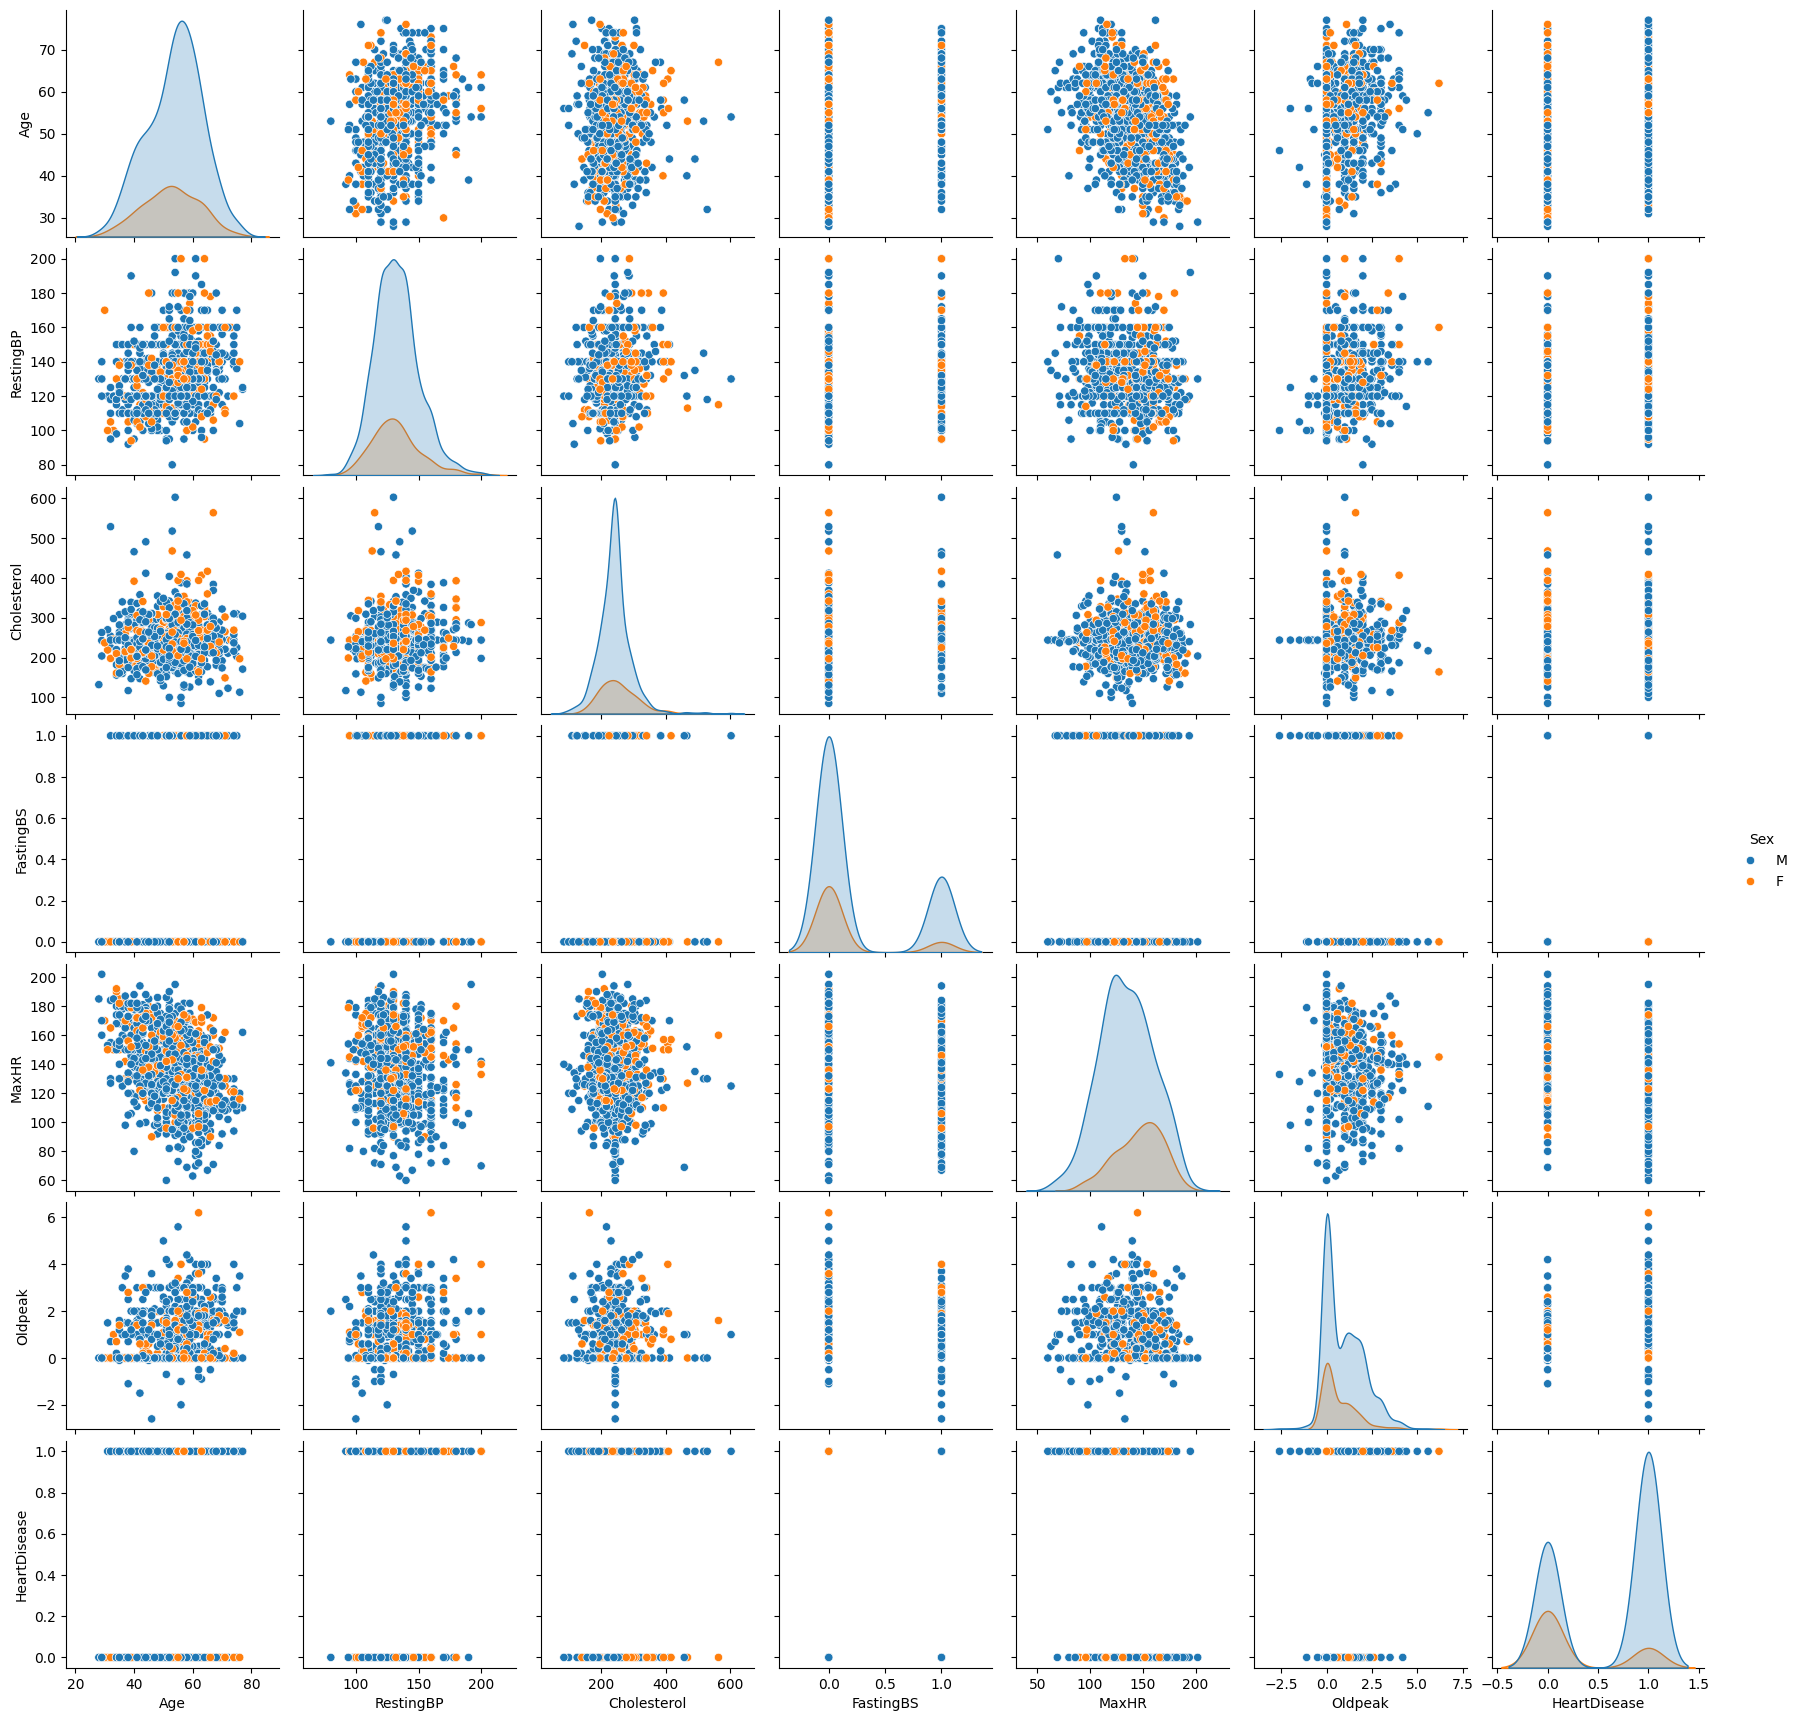

In [25]:
sns.pairplot(df,hue = 'Sex')
plt.show()

In [27]:
df_encode = pd.get_dummies(df)
df_encode = df_encode.astype(int)
df_encode.head()

df_encode.to_csv("Data/cleaned_data.csv", index=False)